# Intelligent Network Security Monitoring and Attack Analysis

## 1. Problem Statement

Network attacks can disrupt services, compromise information, and affect the reliability of computer networks. Analyzing network traffic can help identify patterns associated with benign activity and malicious behavior.

This project uses the CIC-IDS2017 dataset to prepare network traffic data, explore traffic characteristics, and evaluate a baseline machine-learning model for classifying network traffic.

## 2. Project Objectives

- Clean and validate network traffic data.
- Perform exploratory data analysis using statistics and visualizations.
- Identify patterns and class imbalance in network traffic.
- Train a baseline classification model.
- Evaluate model performance using suitable metrics.
- Discuss findings, limitations, and future improvements.

## 3. Dataset Overview

**Dataset:** CIC-IDS2017  
**Subset:** Tuesday Working Hours  
**Target column:** Label  
**Traffic classes:** BENIGN, FTP-Patator, SSH-Patator

**Dataset source:** https://www.unb.ca/cic/datasets/ids-2017.html

## 4. Tools and Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Google Colab.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name, low_memory=False)

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Traffic classes:")
print(df["Label"].value_counts())

Saving CIC_IDS2017_Tuesday_Cleaned.csv to CIC_IDS2017_Tuesday_Cleaned.csv
Dataset shape: (421626, 79)
Missing values: 0
Traffic classes:
Label
BENIGN         412476
FTP-Patator      5931
SSH-Patator      3219
Name: count, dtype: int64


## Data Preparation and Validation

The dataset was cleaned during Task 1 before being used in this final project. The preprocessing included standardizing column names, handling missing and infinite values, removing duplicate records, and validating data types and traffic labels.

The cleaned dataset contains 421,626 records and 79 columns, including 78 numerical features and one categorical target column, `Label`.

The original traffic class distribution has been preserved to support realistic analysis of class imbalance.

In [2]:
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

numeric_df = df.select_dtypes(include=np.number)

print("Infinite values:",
      np.isinf(numeric_df).sum().sum())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nClass distribution:")
display(df["Label"].value_counts().to_frame("Count"))

Dataset shape: (421626, 79)
Duplicate rows: 0
Missing values: 0
Infinite values: 0

Data types:
int64      54
float64    24
object      1
Name: count, dtype: int64

Class distribution:


,Count
Label,
BENIGN,412476
FTP-Patator,5931
SSH-Patator,3219


## Exploratory Data Analysis

Exploratory Data Analysis was performed to understand traffic class distribution, numerical feature characteristics, and relationships between network traffic features. Statistical summaries and visualizations were used to identify patterns that could influence machine-learning model development and evaluation.

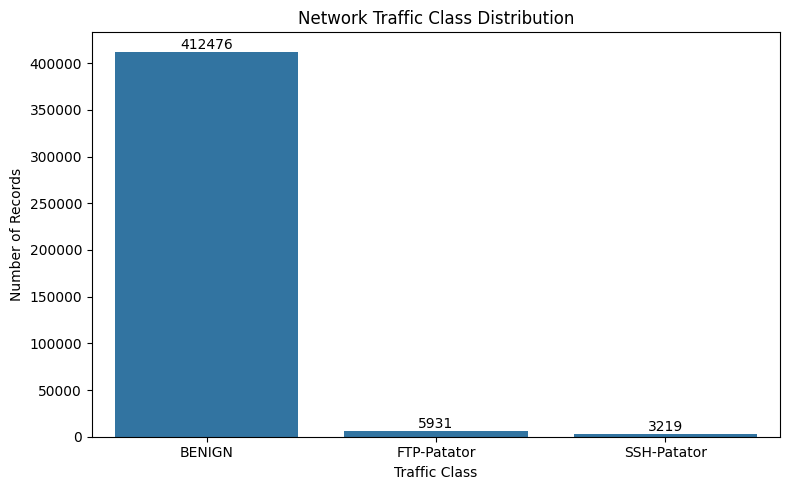


Class percentages:


,Percentage
Label,
BENIGN,97.83
FTP-Patator,1.41
SSH-Patator,0.76


In [3]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x="Label")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Network Traffic Class Distribution")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("\nClass percentages:")
display(
    (df["Label"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

In [4]:
features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s"
]

display(df[features].describe().T)

,count,mean,std,min,25%,50%,75%,max
Flow Duration,421626.0,1.139456e+07,3.027584e+07,-4.0,208.000000,38665.500000,904894.000000,1.200000e+08
Total Fwd Packets,421626.0,1.235701e+01,8.916886e+02,1.0,1.000000,2.000000,4.000000,2.064460e+05
Total Backward Packets,421626.0,1.465610e+01,1.205439e+03,0.0,1.000000,2.000000,3.000000,2.760720e+05
Total Length of Fwd Packets,421626.0,5.573974e+02,5.836682e+03,0.0,31.000000,70.000000,171.000000,2.428415e+06
Flow Bytes/s,421626.0,1.300640e+06,2.352390e+07,0.0,4.816841,2452.123061,18274.342723,2.070000e+09
Flow Packets/s,421626.0,5.084145e+04,2.149420e+05,-2000000.0,9.494729,85.935570,17857.142860,3.000000e+06


In [5]:
print("Negative Flow Duration:",
      (df["Flow Duration"] < 0).sum())

print("Negative Flow Packets/s:",
      (df["Flow Packets/s"] < 0).sum())

print("Negative Flow Bytes/s:",
      (df["Flow Bytes/s"] < 0).sum())

print("\nRecords with negative Flow Duration:")
display(df[df["Flow Duration"] < 0][
    ["Flow Duration", "Flow Packets/s", "Flow Bytes/s", "Label"]
].head(10))

Negative Flow Duration: 16
Negative Flow Packets/s: 16
Negative Flow Bytes/s: 0

Records with negative Flow Duration:


,Flow Duration,Flow Packets/s,Flow Bytes/s,Label
24002,-1,-2000000.0,0.0,BENIGN
26200,-1,-2000000.0,0.0,BENIGN
71098,-1,-2000000.0,0.0,BENIGN
86792,-1,-2000000.0,0.0,BENIGN
99266,-1,-2000000.0,0.0,BENIGN
107586,-1,-2000000.0,0.0,BENIGN
114820,-1,-2000000.0,0.0,BENIGN
119900,-1,-2000000.0,0.0,BENIGN
136665,-1,-2000000.0,0.0,BENIGN
195410,-1,-2000000.0,0.0,BENIGN


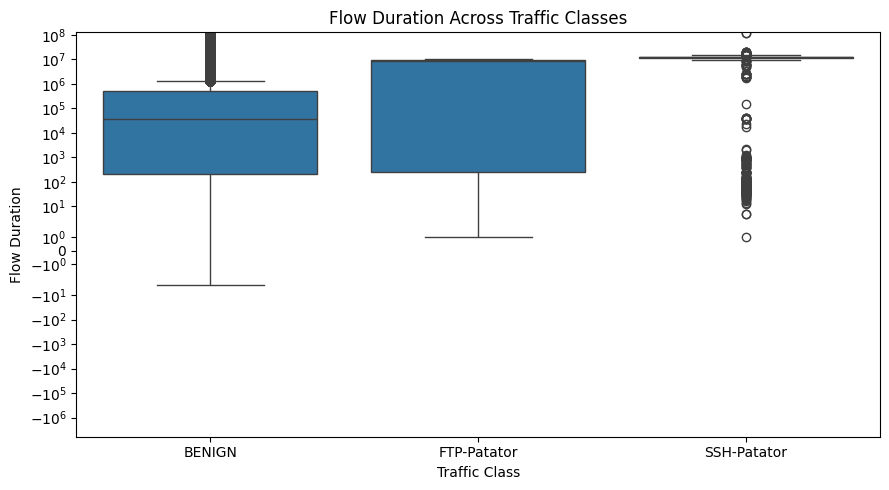

In [6]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Label", y="Flow Duration")

plt.yscale("symlog")
plt.title("Flow Duration Across Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Flow Duration")
plt.tight_layout()
plt.show()

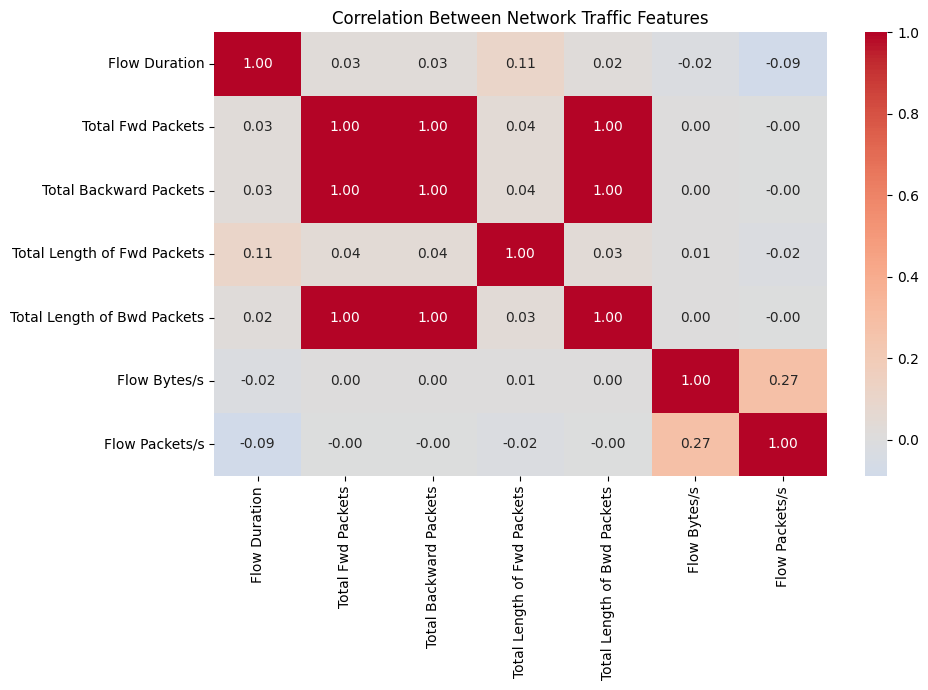

In [7]:
corr_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[corr_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Network Traffic Features")
plt.tight_layout()
plt.show()

In [8]:
print("Packet count correlation:")
print(df["Total Fwd Packets"].corr(
    df["Total Backward Packets"]
))

print("\nClass distribution (%):")
display(
    (df["Label"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

print("\nNegative value checks:")
for col in ["Flow Duration", "Flow Packets/s", "Flow Bytes/s"]:
    print(col, ":", (df[col] < 0).sum())

Packet count correlation:
0.9994769973736908

Class distribution (%):


,Percentage
Label,
BENIGN,97.83
FTP-Patator,1.41
SSH-Patator,0.76



Negative value checks:
Flow Duration : 16
Flow Packets/s : 16
Flow Bytes/s : 0


In [9]:
negative_duration = df["Flow Duration"] < 0
negative_rate = df["Flow Packets/s"] < 0

print("Negative duration:", negative_duration.sum())
print("Negative packet rate:", negative_rate.sum())
print("Both conditions:", (negative_duration & negative_rate).sum())

display(
    df.loc[
        negative_duration | negative_rate,
        ["Flow Duration", "Flow Packets/s", "Flow Bytes/s", "Label"]
    ].head(10)
)

Negative duration: 16
Negative packet rate: 16
Both conditions: 16


,Flow Duration,Flow Packets/s,Flow Bytes/s,Label
24002,-1,-2000000.0,0.0,BENIGN
26200,-1,-2000000.0,0.0,BENIGN
71098,-1,-2000000.0,0.0,BENIGN
86792,-1,-2000000.0,0.0,BENIGN
99266,-1,-2000000.0,0.0,BENIGN
107586,-1,-2000000.0,0.0,BENIGN
114820,-1,-2000000.0,0.0,BENIGN
119900,-1,-2000000.0,0.0,BENIGN
136665,-1,-2000000.0,0.0,BENIGN
195410,-1,-2000000.0,0.0,BENIGN


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model_df = df.copy()

invalid = (
    (model_df["Flow Duration"] < 0) |
    (model_df["Flow Packets/s"] < 0)
)

model_df = model_df.loc[~invalid].copy()

numeric_cols = model_df.select_dtypes(include=np.number).columns

finite_rows = np.isfinite(
    model_df[numeric_cols].to_numpy()
).all(axis=1)

model_df = model_df.loc[finite_rows].copy()

X = model_df.drop(columns=["Label"])
y = model_df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Model training completed!")

Training records: 337288
Testing records: 84322
Model training completed!


In [11]:
y_pred = model.predict(X_test)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 4))

print("Macro Precision:",
      round(precision_score(
          y_test, y_pred, average="macro", zero_division=0
      ), 4))

print("Macro Recall:",
      round(recall_score(
          y_test, y_pred, average="macro", zero_division=0
      ), 4))

print("Macro F1-score:",
      round(f1_score(
          y_test, y_pred, average="macro", zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 1.0
Balanced Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     82492
 FTP-Patator       1.00      1.00      1.00      1186
 SSH-Patator       1.00      1.00      1.00       644

    accuracy                           1.00     84322
   macro avg       1.00      1.00      1.00     84322
weighted avg       1.00      1.00      1.00     84322



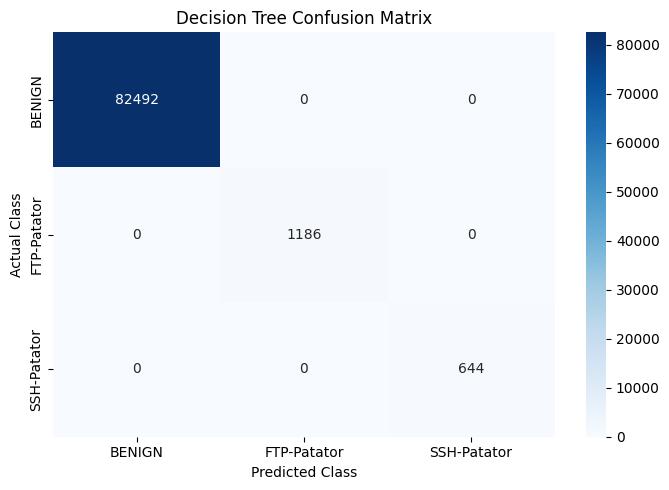

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     82492
 FTP-Patator       1.00      1.00      1.00      1186
 SSH-Patator       1.00      1.00      1.00       644

    accuracy                           1.00     84322
   macro avg       1.00      1.00      1.00     84322
weighted avg       1.00      1.00      1.00     84322

Training Accuracy: 1.0
Testing Accuracy: 1.0

Top 10 Feature Importances:


,Importance
Destination Port,0.993765
Subflow Bwd Bytes,0.002356
Total Fwd Packets,0.001794
min_seg_size_forward,0.000594
Init_Win_bytes_backward,0.000545
Fwd Header Length,0.000520
Down/Up Ratio,0.000170
Fwd IAT Min,0.000167
Init_Win_bytes_forward,0.000039
Subflow Fwd Packets,0.000031


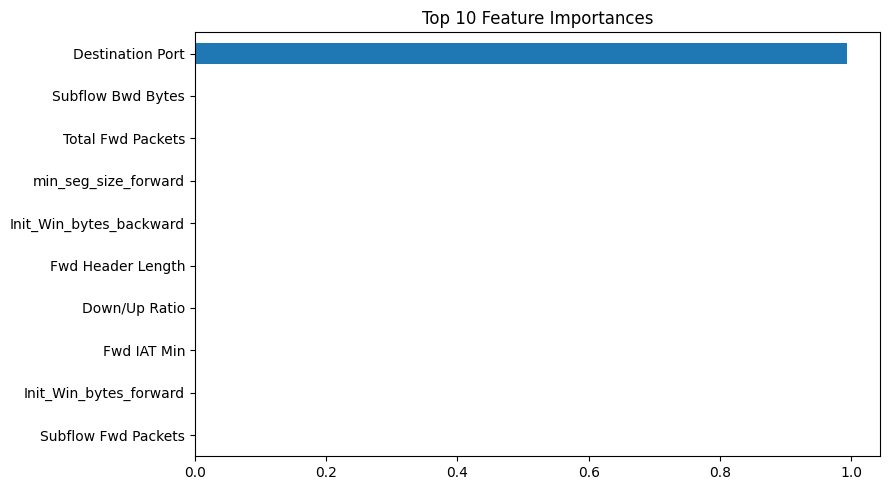

In [13]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Training Accuracy:", round(model.score(X_train, y_train), 4))
print("Testing Accuracy:", round(model.score(X_test, y_test), 4))

print("\nTop 10 Feature Importances:")
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(importance.head(10).to_frame("Importance"))

importance.head(10).sort_values().plot(
    kind="barh", figsize=(9, 5), title="Top 10 Feature Importances"
)
plt.tight_layout()
plt.show()

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import balanced_accuracy_score, f1_score

# Model without Destination Port
X_train_no_port = X_train.drop(columns=["Destination Port"])
X_test_no_port = X_test.drop(columns=["Destination Port"])

model_no_port = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

model_no_port.fit(X_train_no_port, y_train)

pred_no_port = model_no_port.predict(X_test_no_port)

print("MODEL COMPARISON")
print("-" * 40)

print("With Destination Port:")
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 4))
print("Macro F1:",
      round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nWithout Destination Port:")
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, pred_no_port), 4))
print("Macro F1:",
      round(f1_score(y_test, pred_no_port, average="macro"), 4))

print("\nClassification Report Without Destination Port:")
print(classification_report(y_test, pred_no_port, zero_division=0))

MODEL COMPARISON
----------------------------------------
With Destination Port:
Balanced Accuracy: 1.0
Macro F1: 1.0

Without Destination Port:
Balanced Accuracy: 0.9986
Macro F1: 0.997

Classification Report Without Destination Port:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     82492
 FTP-Patator       0.99      1.00      0.99      1186
 SSH-Patator       1.00      1.00      1.00       644

    accuracy                           1.00     84322
   macro avg       1.00      1.00      1.00     84322
weighted avg       1.00      1.00      1.00     84322



In [15]:
train_rows = set(
    pd.util.hash_pandas_object(X_train, index=False).values
)

test_rows = set(
    pd.util.hash_pandas_object(X_test, index=False).values
)

overlap = train_rows.intersection(test_rows)

print("Unique training feature rows:", len(train_rows))
print("Unique testing feature rows:", len(test_rows))
print("Overlapping feature-row hashes:", len(overlap))
print("Overlap percentage of test rows:",
      round(len(overlap) / len(X_test) * 100, 4), "%")

Unique training feature rows: 337288
Unique testing feature rows: 84322
Overlapping feature-row hashes: 0
Overlap percentage of test rows: 0.0 %


## Key Findings and Insights

### 1. Significant Class Imbalance
The dataset contains 97.83% BENIGN traffic, 1.41% FTP-Patator traffic, and 0.76% SSH-Patator traffic. This imbalance makes balanced accuracy, per-class recall, and macro F1-score important evaluation metrics.

### 2. Strong Feature Correlation
The correlation between `Total Fwd Packets` and `Total Backward Packets` is approximately 0.9995. This unusually strong relationship warrants further investigation and may indicate overlapping information between these features.

### 3. Destination Port Importance
The baseline Decision Tree assigns nearly all feature importance to `Destination Port`. This suggests that port information strongly influences the model's predictions on this dataset.

### 4. Performance Without Destination Port
After removing `Destination Port`, the model achieved a balanced accuracy of 0.9986 and a macro F1-score of 0.997. This indicates that the remaining features still provide strong predictive information within the current random train-test split.

### 5. Unusual Numerical Values
Sixteen records contained negative `Flow Duration` values, and sixteen contained negative `Flow Packets/s` values. These records were excluded from the modeling dataset because negative durations and packet rates are not physically meaningful. The underlying cause should be investigated further.

## Model Evaluation

A Decision Tree classifier with a maximum depth of 10 and balanced class weights was trained using an 80/20 stratified train-test split.

The model achieved perfect-looking results on the held-out test set when all features were included. After removing `Destination Port`, performance decreased slightly but remained high.

These results should be interpreted cautiously. A random split may not adequately test generalization to different network environments, days, or attack scenarios. Further validation is required before considering the model reliable for real-world intrusion detection.

## Limitations

- The dataset has a substantial class imbalance.
- The model relies heavily on `Destination Port`.
- Random train-test evaluation may overestimate performance on unseen network environments.
- Checking for exact duplicate feature rows does not rule out all forms of data leakage.
- Performance on CIC-IDS2017 does not guarantee equivalent performance on real-world network traffic.

## Conclusion

This project combined data preparation, exploratory data analysis, and baseline machine-learning classification using CIC-IDS2017 network traffic data.

The analysis identified significant class imbalance, strong relationships between numerical features, and heavy reliance on destination-port information. The baseline model achieved high test performance, but further evaluation on independent traffic scenarios is needed to assess its generalization capability.

Future work includes comparing additional classifiers, investigating feature importance, and evaluating the model on independently collected network traffic.